# 01 - Global Exploratory Data Analysis
**Project:** Crop Yield Prediction using ML and Explainable AI (PAI101)

This notebook covers three of the four types of data analysis from the syllabus:
**descriptive** (what does the data look like?), **exploratory** (what patterns are there?) and **inferential** (are the patterns statistically real?). The fourth type, **predictive**, is in notebook 02.

Target: `hg/ha_yield` = crop yield in hectograms per hectare (10,000 hg/ha = 1 t/ha).

In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import Markdown, display
from src import config as C, data
%matplotlib inline
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160)
def save(name):
    plt.tight_layout(); plt.savefig(C.FIG_DIR / name, dpi=130); plt.show()

## 1. Cleaning log
We drop the junk index column and remove exact duplicate rows. Outliers in yield are *reported* but kept (see `src/data.py` for why).

In [2]:
raw = data.load_raw()
df = data.clean()
print('missing values per column:', raw.isna().sum().sum())

rows raw=28242  missing cells=0  duplicates dropped=2310  final=25932
target IQR outliers: 1918 (7.4%) above 230426 hg/ha -> KEPT (legitimate root-crop yields)
missing values per column: 0


## 2. Descriptive analysis

In [3]:
print("shape:", df.shape)
display(df.dtypes.to_frame("dtype"))
display(df.describe().T.round(2))
print("year range:", df.Year.min(), "-", df.Year.max())
print("countries:", df.Area.nunique(), "| crops:", df.Item.nunique())
print(sorted(df.Item.unique()))

shape: (25932, 7)


,dtype
Area,str
Item,str
Year,int64
hg/ha_yield,int64
average_rain_fall_mm_per_year,float64
pesticides_tonnes,float64
avg_temp,float64


,count,mean,std,min,25%,50%,75%,max
Year,25932.0,2001.56,7.06,1990.00,1995.00,2001.00,2008.00,2013.00
hg/ha_yield,25932.0,76978.13,84647.61,50.00,19996.00,39530.00,104168.00,501412.00
average_rain_fall_mm_per_year,25932.0,1146.84,717.39,51.00,593.00,1083.00,1668.00,3240.00
pesticides_tonnes,25932.0,34782.57,57228.57,0.04,1597.00,15373.00,45620.00,367778.00
avg_temp,25932.0,20.42,6.44,1.30,16.58,21.42,26.06,30.65


year range: 1990 - 2013
countries: 101 | crops: 10
['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']


Each row is one **country-crop-year**. Notice that rainfall and temperature are *country-year* values (the same for every crop in a country-year) - they describe the country's climate, not the individual farm.

## 3. Exploratory analysis
### 3.1 Target distribution
Yield is strongly right-skewed (a few crops like potatoes and cassava yield 5-10x more than cereals). A log transform makes it more bell-shaped.

skewness raw: 1.81 | log: -0.07


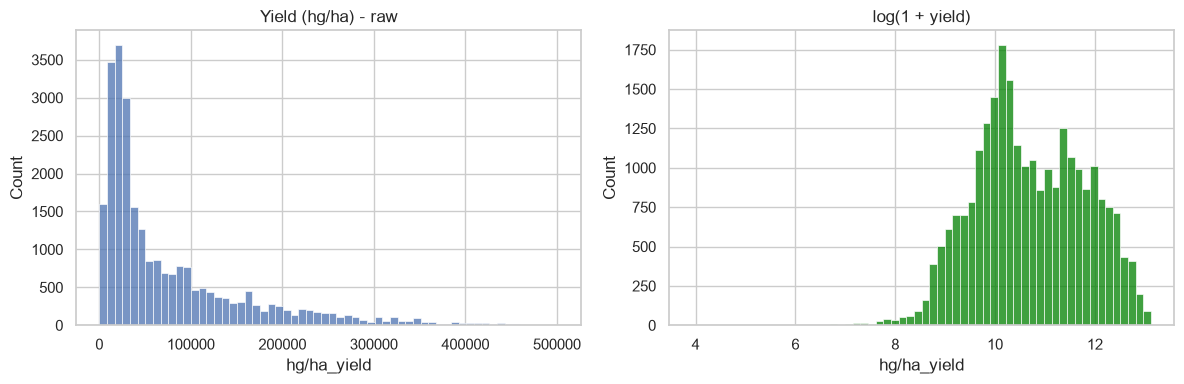

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[C.G_TARGET], bins=60, ax=ax[0]); ax[0].set_title("Yield (hg/ha) - raw")
sns.histplot(np.log1p(df[C.G_TARGET]), bins=60, ax=ax[1], color="green"); ax[1].set_title("log(1 + yield)")
print("skewness raw:", round(df[C.G_TARGET].skew(), 2), "| log:", round(np.log1p(df[C.G_TARGET]).skew(), 2))
save("eda_target_distribution.png")

### 3.2 Yield by crop

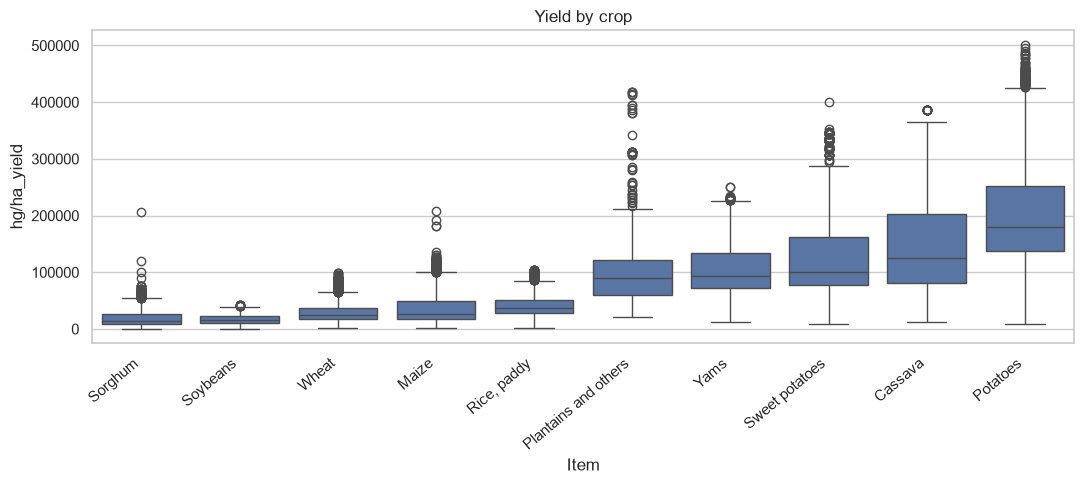

,count,mean,median
Item,,,
Sorghum,2770,19100.0,13548.0
Soybeans,2940,16992.0,16006.0
Wheat,3539,30126.0,25296.0
Maize,3824,37139.0,25557.0
"Rice, paddy",3091,41296.0,36408.0
Plantains and others,556,106041.0,89860.0
Yams,774,112106.0,92593.0
Sweet potatoes,2593,119657.0,99940.0
Cassava,1889,145650.0,125305.0


In [5]:
order = df.groupby("Item")[C.G_TARGET].median().sort_values().index
plt.figure(figsize=(11, 5)); sns.boxplot(data=df, x="Item", y=C.G_TARGET, order=order)
plt.xticks(rotation=40, ha="right"); plt.title("Yield by crop"); save("eda_yield_by_crop.png")
display(df.groupby("Item")[C.G_TARGET].agg(["count", "mean", "median"]).sort_values("median").round(0))

Crop type is clearly the biggest separator: root crops (potatoes, cassava, sweet potatoes) vs cereals/pulses. The IQR 'outliers' flagged earlier are mostly these high-yield root crops, so they are genuine.

### 3.3 Top 10 countries by average yield

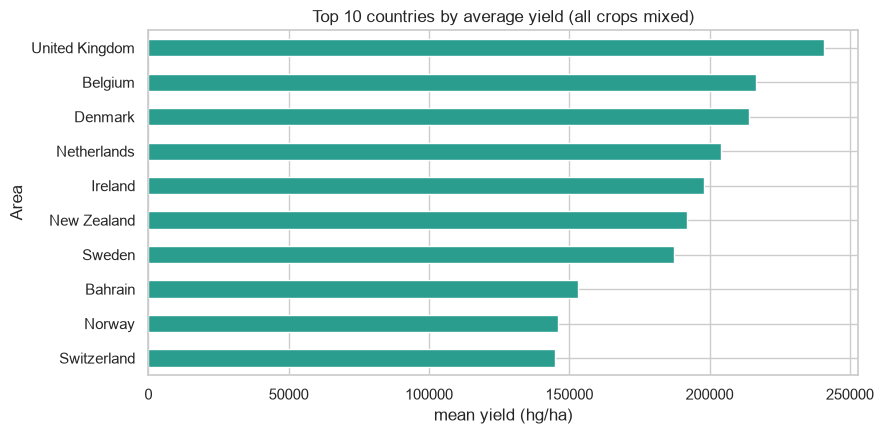

,hg/ha_yield
Area,
United Kingdom,240956.0
Belgium,216468.0
Denmark,214033.0
Netherlands,204151.0
Ireland,197914.0
New Zealand,191932.0
Sweden,187406.0
Bahrain,153238.0
Norway,146115.0


In [6]:
top = df.groupby("Area")[C.G_TARGET].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 4.5)); top[::-1].plot.barh(color="#2a9d8f"); plt.xlabel("mean yield (hg/ha)")
plt.title("Top 10 countries by average yield (all crops mixed)"); save("eda_top_countries.png")
display(top.round(0).to_frame())

### 3.4 Yield trend over years (most common crops)

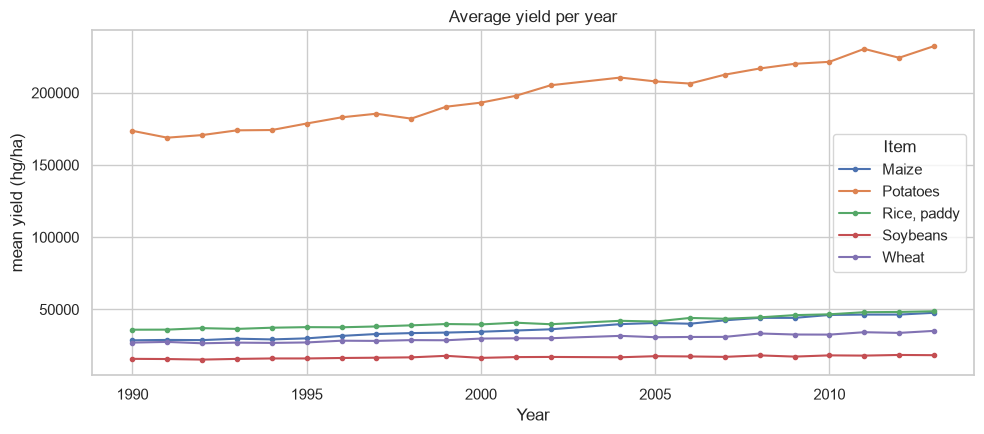

linear trend (hg/ha per year): {'Maize': 914, 'Potatoes': 2810, 'Rice, paddy': 567, 'Soybeans': 121, 'Wheat': 352}


In [7]:
crops = df.Item.value_counts().head(5).index
tr = df[df.Item.isin(crops)].groupby(["Year", "Item"])[C.G_TARGET].mean().unstack()
tr.plot(figsize=(10, 4.5), marker="o", ms=3); plt.ylabel("mean yield (hg/ha)"); plt.title("Average yield per year")
save("eda_yield_trend.png")
slope = {c: stats.linregress(tr.index, tr[c]).slope for c in tr.columns}
print("linear trend (hg/ha per year):", {k: round(v) for k, v in slope.items()})

### 3.5 Rainfall, temperature and pesticides vs yield

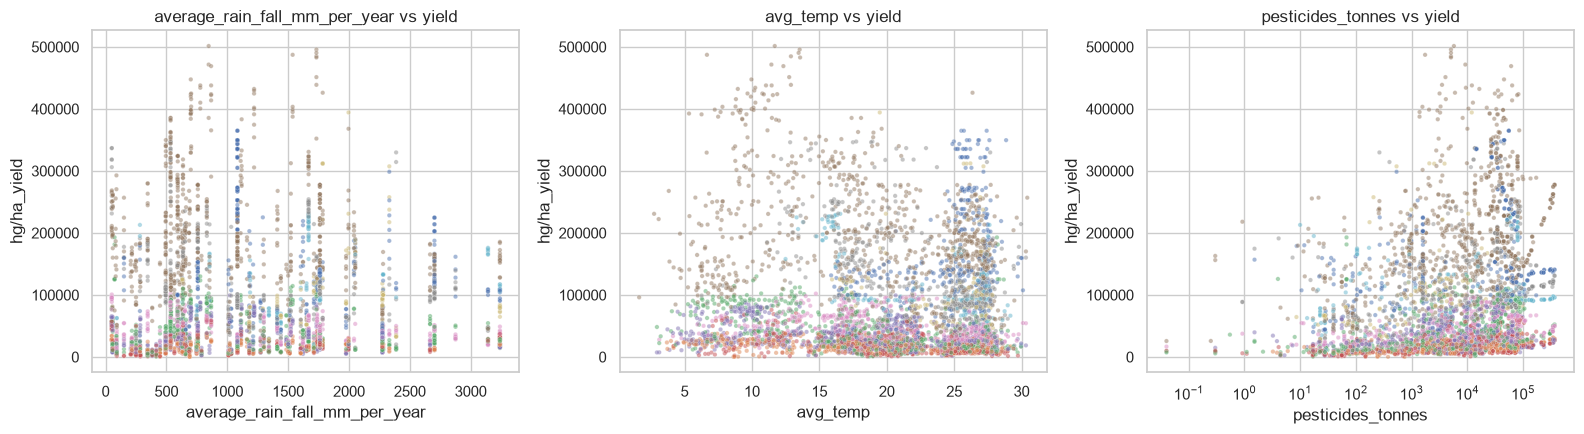

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, [C.G_RAIN, C.G_TEMP, C.G_PEST]):
    sns.scatterplot(data=df.sample(5000, random_state=42), x=col, y=C.G_TARGET, hue="Item", s=10, alpha=.5, ax=a, legend=False)
    a.set_title(f"{col} vs yield")
ax[2].set_xscale("log")
save("eda_scatter_drivers.png")

There is **no clean straight-line relation** between any single weather variable and yield: the crop-type effect dominates and hides the weaker climate effect. This is why we need a model that can combine features non-linearly.

### 3.6 Correlation heatmap

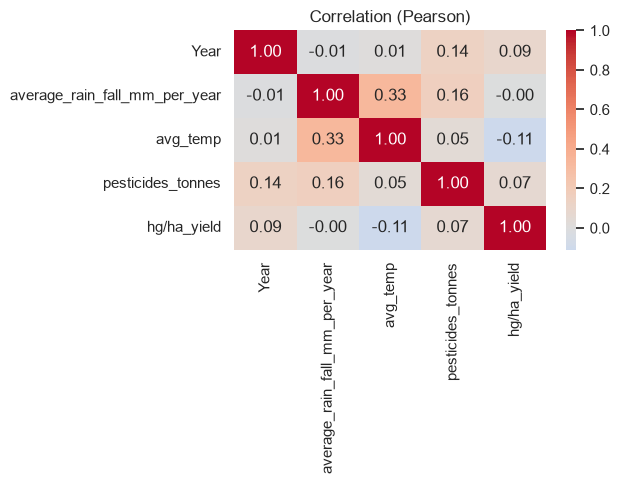

In [9]:
corr = df[[C.G_YEAR, C.G_RAIN, C.G_TEMP, C.G_PEST, C.G_TARGET]].corr()
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (Pearson)"); save("eda_correlation_heatmap.png")

## 4. Inferential analysis
### 4.1 One-way ANOVA: does mean yield differ between crops?
*H0:* all crops have the same mean yield. *H1:* at least one crop differs. We use a 5% significance level.

In [10]:
groups = [g[C.G_TARGET].values for _, g in df.groupby("Item")]
F, p_anova = stats.f_oneway(*groups)
H, p_kw = stats.kruskal(*groups)   # non-parametric check, since yield is skewed
eta2 = 1 - sum(((g - g.mean())**2).sum() for g in groups) / ((df[C.G_TARGET] - df[C.G_TARGET].mean())**2).sum()
print(f"ANOVA F = {F:.1f}, p = {p_anova:.3g} (0 = below machine precision) | Kruskal-Wallis H = {H:.1f}, p = {p_kw:.3g} | eta^2 = {eta2:.3f}")

ANOVA F = 4299.7, p = 0 (0 = below machine precision) | Kruskal-Wallis H = 17393.8, p = 0 | eta^2 = 0.599


In [11]:
display(Markdown(f"**Interpretation.** p < 0.001, so we **reject H0**: mean yield differs significantly between crops. "
 f"The effect size is huge (eta² = {eta2:.2f}: crop type alone explains about {eta2*100:.0f}% of the variance in yield). "
 "Because yield is skewed (ANOVA assumes roughly normal groups) we confirmed it with the non-parametric Kruskal-Wallis test, which agrees."))

**Interpretation.** p < 0.001, so we **reject H0**: mean yield differs significantly between crops. The effect size is huge (eta² = 0.60: crop type alone explains about 60% of the variance in yield). Because yield is skewed (ANOVA assumes roughly normal groups) we confirmed it with the non-parametric Kruskal-Wallis test, which agrees.

### 4.2 Correlation significance: temperature vs yield
*H0:* true correlation = 0.

In [12]:
r, p_r = stats.pearsonr(df[C.G_TEMP], df[C.G_TARGET])
rho, p_s = stats.spearmanr(df[C.G_TEMP], df[C.G_TARGET])
# the pooled correlation hides the crop effect; check inside one crop too
w = df[df.Item == "Wheat"]; rw, pw = stats.pearsonr(w[C.G_TEMP], w[C.G_TARGET])
print(f"all crops: Pearson r={r:.3f} (p={p_r:.2g}), Spearman rho={rho:.3f} (p={p_s:.2g}); wheat only: r={rw:.3f} (p={pw:.2g})")

all crops: Pearson r=-0.110 (p=4e-71), Spearman rho=-0.101 (p=2.5e-60); wheat only: r=-0.366 (p=1.4e-112)


In [13]:
display(Markdown(f"**Interpretation.** With n = {len(df):,} rows even a small correlation is 'significant' (p = {p_r:.2g}), but the **size** matters: r = {r:.2f} is "
 f"{'weak' if abs(r) < 0.3 else 'moderate'} (temperature explains only {r**2*100:.1f}% of yield variance when all crops are mixed). "
 f"Inside wheat alone, r = {rw:.2f}, showing the pooled number is affected by crop mix (Simpson's-paradox-like). "
 "Statistical significance is not the same as practical importance, and correlation is not causation."))

**Interpretation.** With n = 25,932 rows even a small correlation is 'significant' (p = 4e-71), but the **size** matters: r = -0.11 is weak (temperature explains only 1.2% of yield variance when all crops are mixed). Inside wheat alone, r = -0.37, showing the pooled number is affected by crop mix (Simpson's-paradox-like). Statistical significance is not the same as practical importance, and correlation is not causation.

## 5. Key insights

In [14]:
cm = df.groupby("Item")[C.G_TARGET].median().sort_values()
cy = df.groupby("Area")[C.G_TARGET].mean().sort_values(ascending=False)
ins = [
 f"**Crop type dominates yield.** ANOVA F = {F:.0f} (p < 0.001), eta² = {eta2:.2f}. Median yield ranges from {cm.iloc[0]:,.0f} hg/ha ({cm.index[0]}) to {cm.iloc[-1]:,.0f} hg/ha ({cm.index[-1]}).",
 f"**Yield is heavily right-skewed** (skewness {df[C.G_TARGET].skew():.2f}; {np.log1p(df[C.G_TARGET]).skew():.2f} after log). IQR flags {data.iqr_outlier_report(df[C.G_TARGET])['pct']:.1f}% of rows as outliers, but these are real root-crop yields, so we keep them.",
 f"**Geography matters.** Highest average yield: {cy.index[0]} ({cy.iloc[0]:,.0f} hg/ha); lowest: {cy.index[-1]} ({cy.iloc[-1]:,.0f} hg/ha).",
 f"**Weather alone is a weak linear predictor.** Pooled temperature-yield r = {r:.2f}; rainfall-yield r = {corr.loc[C.G_RAIN, C.G_TARGET]:.2f}; pesticides-yield r = {corr.loc[C.G_PEST, C.G_TARGET]:.2f}. Relationships are non-linear and crop-specific.",
 f"**Yields trend upward over time** for most crops (e.g. linear slopes: " + ", ".join(f"{k} {v:+,.0f}" for k, v in slope.items()) + " hg/ha per year), reflecting technology and management improvements.",
 f"**Data caveat:** {df.Area.nunique()} countries but only {df.Year.nunique()} years ({df.Year.min()}-{df.Year.max()}); climate variables are country-level annual averages, so farm-level conditions are invisible.",
 "**Pesticide use is skewed and confounded:** big agricultural countries use far more tonnes; this reflects scale, not necessarily effectiveness (correlation is not causation).",
]
display(Markdown("\n".join(f"{i+1}. {t}" for i, t in enumerate(ins))))

1. **Crop type dominates yield.** ANOVA F = 4300 (p < 0.001), eta² = 0.60. Median yield ranges from 13,548 hg/ha (Sorghum) to 180,322 hg/ha (Potatoes).
2. **Yield is heavily right-skewed** (skewness 1.81; -0.07 after log). IQR flags 7.4% of rows as outliers, but these are real root-crop yields, so we keep them.
3. **Geography matters.** Highest average yield: United Kingdom (240,956 hg/ha); lowest: Botswana (7,354 hg/ha).
4. **Weather alone is a weak linear predictor.** Pooled temperature-yield r = -0.11; rainfall-yield r = -0.00; pesticides-yield r = 0.07. Relationships are non-linear and crop-specific.
5. **Yields trend upward over time** for most crops (e.g. linear slopes: Maize +914, Potatoes +2,810, Rice, paddy +567, Soybeans +121, Wheat +352 hg/ha per year), reflecting technology and management improvements.
6. **Data caveat:** 101 countries but only 23 years (1990-2013); climate variables are country-level annual averages, so farm-level conditions are invisible.
7. **Pesticide use is skewed and confounded:** big agricultural countries use far more tonnes; this reflects scale, not necessarily effectiveness (correlation is not causation).